## Conclusion

In this project, we successfully developed an Iris Flower Classification system using Machine Learning.

We explored the dataset, performed data visualization, selected important features, and trained two classification algorithms: Logistic Regression and Decision Tree.

Both models were evaluated using accuracy, confusion matrices, and classification reports. The model with the higher accuracy was selected as the best-performing model.

This project demonstrates how machine learning can be used to classify flower species based on their physical measurements.

Logistic Regression: 0.9666666666666667
Decision Tree: 0.9333333333333333

Best Performing Model: Logistic Regression
Best Accuracy: 96.66666666666667 %


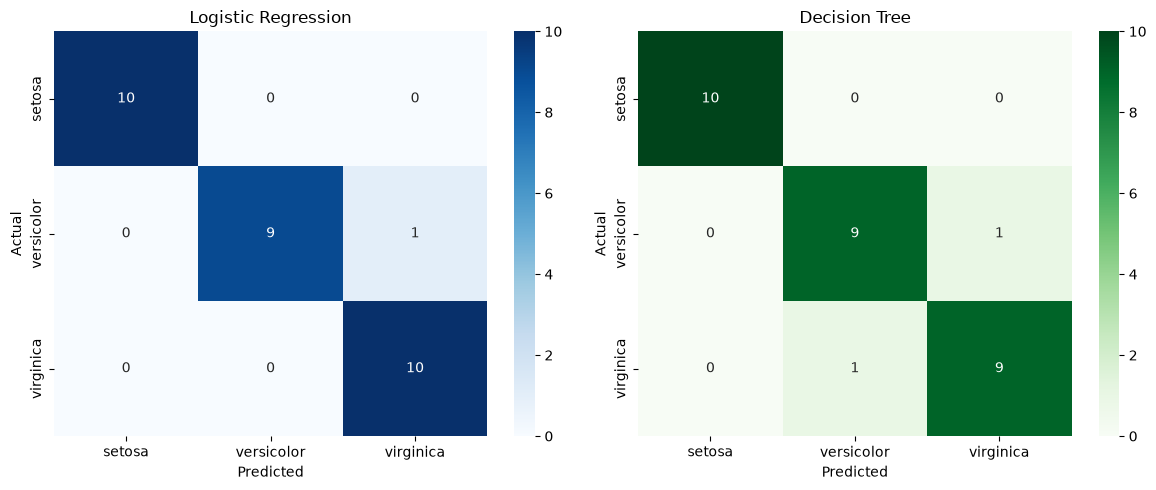

In [8]:
# Plot confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(confusion_matrix(y_test, pred1),
            annot=True, fmt='d', cmap='Blues',
            xticklabels=iris.target_names,
            yticklabels=iris.target_names, ax=axes[0])

axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(confusion_matrix(y_test, pred2),
            annot=True, fmt='d', cmap='Greens',
            xticklabels=iris.target_names,
            yticklabels=iris.target_names, ax=axes[1])

axes[1].set_title("Decision Tree")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [7]:
from sklearn.metrics import confusion_matrix, classification_report

# Logistic Regression evaluation
print("LOGISTIC REGRESSION")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, pred1))
print("\nClassification Report:")
print(classification_report(y_test, pred1, target_names=iris.target_names))

# Decision Tree evaluation
print("\nDECISION TREE")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, pred2))
print("\nClassification Report:")
print(classification_report(y_test, pred2, target_names=iris.target_names))

LOGISTIC REGRESSION

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


DECISION TREE

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Create the models
model1 = LogisticRegression(max_iter=200)
model2 = DecisionTreeClassifier(random_state=42)

# Train both models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)

# Make predictions
pred1 = model1.predict(X_test)
pred2 = model2.predict(X_test)

# Calculate accuracy
print("Logistic Regression Accuracy:",
      accuracy_score(y_test, pred1))

print("Decision Tree Accuracy:",
      accuracy_score(y_test, pred2))

Logistic Regression Accuracy: 0.9666666666666667
Decision Tree Accuracy: 0.9333333333333333


In [5]:
from sklearn.model_selection import train_test_split

# Select input features and target
X = df[iris.feature_names]
y = df['species']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


## Feature Selection

The Iris dataset contains four input features:

1. Sepal Length
2. Sepal Width
3. Petal Length
4. Petal Width

All four features are selected for model training. Based on the visualizations, petal length and petal width show clearer differences between the three species. These features are particularly useful for classification.

Therefore, all four measurements will be used to train the machine learning models.

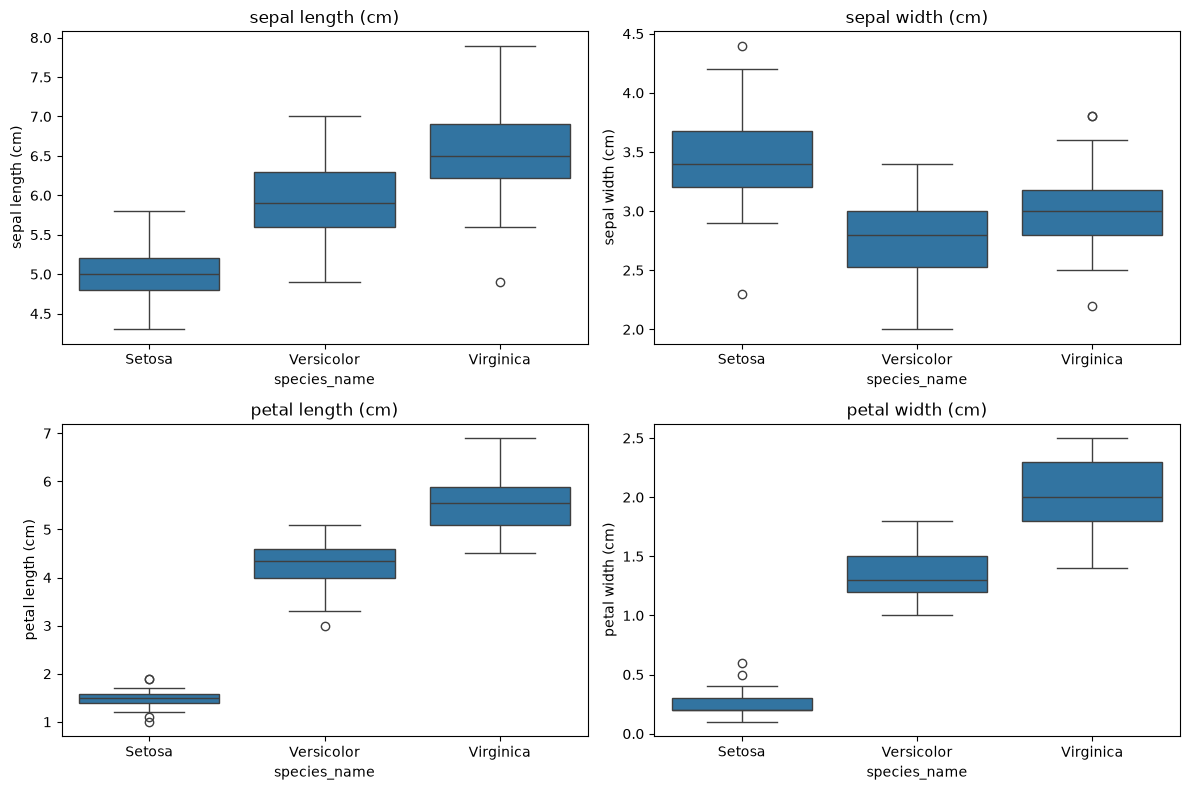

In [4]:
# Create boxplots for all four measurements
features = iris.feature_names

plt.figure(figsize=(12, 8))

for i, feature in enumerate(features):
    plt.subplot(2, 2, i + 1)
    sns.boxplot(data=df, x='species_name', y=feature)
    plt.title(feature)

plt.tight_layout()
plt.show()

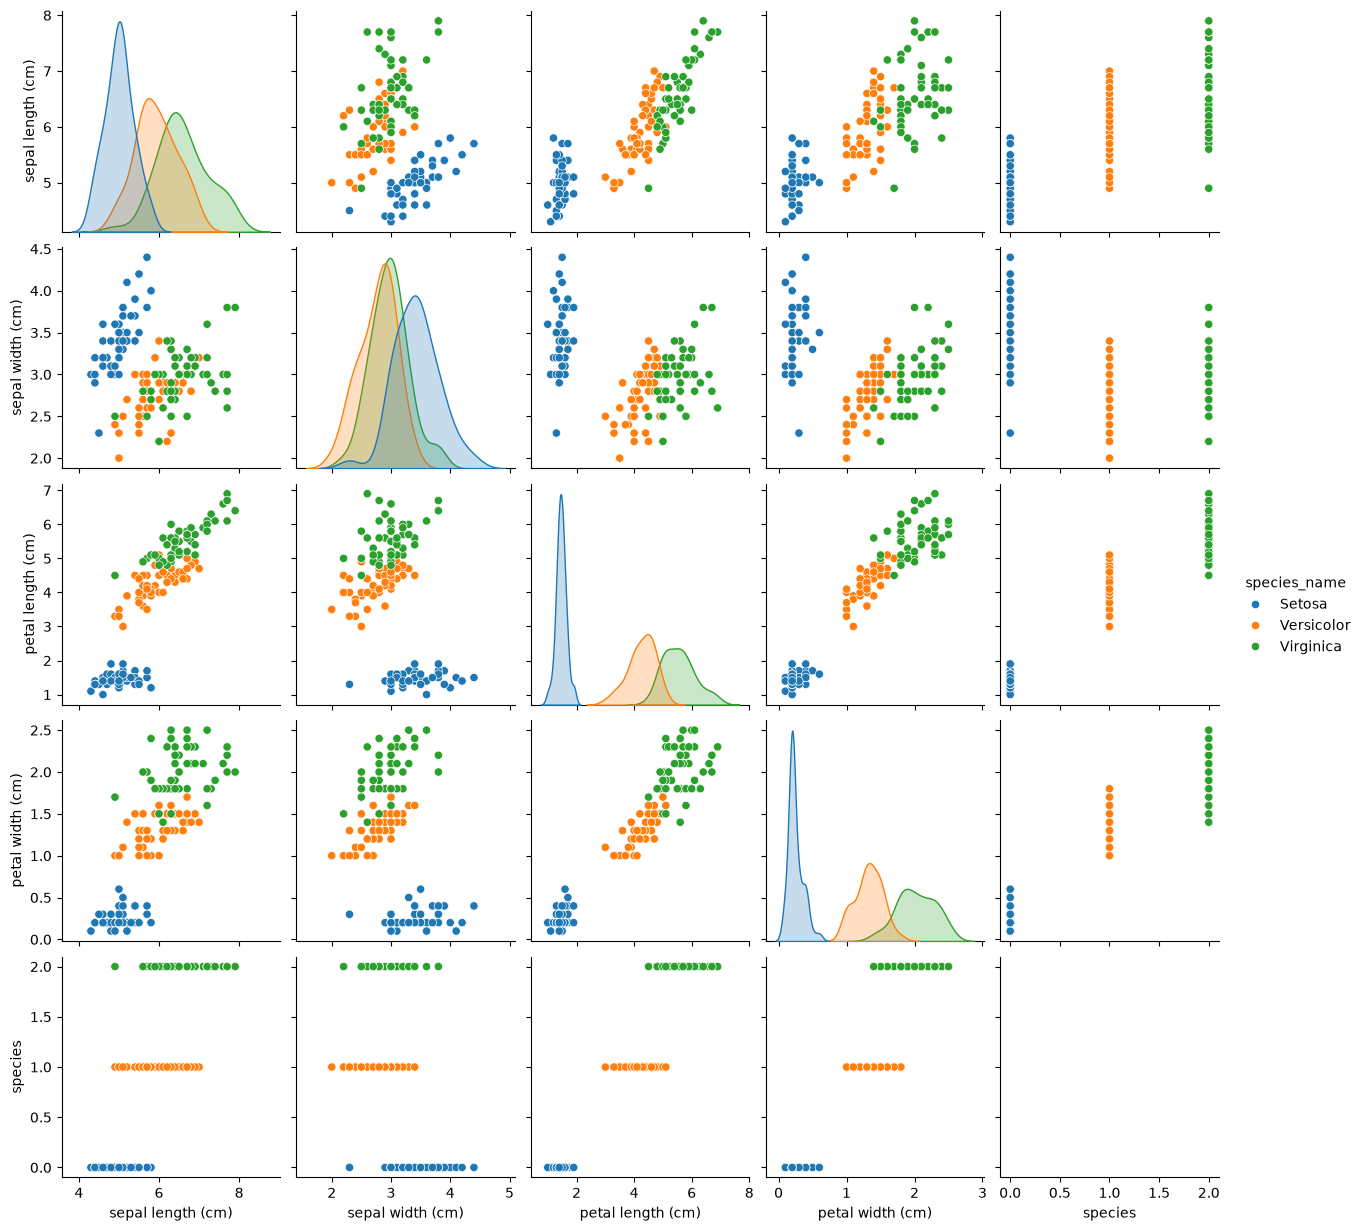

In [3]:
# Convert species numbers into flower names
df['species_name'] = df['species'].map({
    0: 'Setosa',
    1: 'Versicolor',
    2: 'Virginica'
})

# Pairplot to compare all flower measurements
sns.pairplot(df, hue='species_name')
plt.show()

In [2]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column names and data types
print("\nDataset Information:")
df.info()

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Display statistical summary
print("\nStatistical Summary:")
df.describe()

Dataset Shape: (150, 5)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB

Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

Statistical Summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

# Load the Iris dataset
iris = load_iris()

# Create a DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = iris.target

# Display first five rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


# Iris Flower Classification Using Machine Learning

## Internship Project – Oasis Infobyte

**Objective:** To classify Iris flowers into three species — Setosa, Versicolor, and Virginica — using machine learning algorithms.

**Tools & Libraries:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn.